# Semana 18: Proyecto final: codificación corriente → frecuencia en el LIF

**Pregunta:** modelo simple que mejor predice la frecuencia de disparo del LIF para corrientes
**más altas** que las vistas al ajustar (extrapolación).

## Datos

31 corrientes de 0 a 3 nA; la frecuencia "observada" son los spikes en 500 ms / 0.5 s
(resolución 2 Hz). Partición **ordenada**: se ajusta con 0-2.1 nA y se evalúa en 2.2-3.0 nA.

## Modelos comparados

| Modelo | Ecuación | Parámetros ajustados |
|---|---|---|
| Línea base | $\hat f = \bar f_\text{train}$ | 1 |
| Lineal | $\hat f = \beta_0 + \beta_1 I$ (todos los puntos) | 2 |
| Umbral-lineal | $\hat f = \max\big(0, \beta_0 + \beta_1 I\big)$, ajustado solo con $f > 0$ | 2 |
| Teoría LIF | $f(I) = \big[t_\text{ref} + \tau_m \ln\frac{RI}{RI - 15}\big]^{-1}$ | 0 (referencia) |

**Hipótesis (escrita antes del análisis):** el modelo lineal falla porque mezcla la zona
subumbral (f = 0) con la supraumbral; el umbral-lineal reduce el error de prueba al menos a la
mitad. La teoría LIF da el error mínimo alcanzable, limitado por la resolución de 2 Hz.

**Criterio de éxito:** RMSE(umbral-lineal) < 0.5 × RMSE(lineal) en las corrientes de prueba.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience import fit_linear_model, lif_firing_rate, simulate_lif
from computational_neuroscience.outputs import save_data, save_figure, save_text

WEEK = 18
WINDOW_S = 0.5
SPLIT = 22
currents = np.linspace(0.0, 3.0, 31)
rates = np.array([simulate_lif(current, duration_ms=WINDOW_S * 1000).spike_times_ms.size / WINDOW_S for current in currents])
train, test = np.arange(SPLIT), np.arange(SPLIT, currents.size)


def rmse(predicted: np.ndarray) -> float:
    return float(np.sqrt(np.mean((rates[test] - predicted) ** 2)))


linear = fit_linear_model(currents[train, None], rates[train])
firing_train = train[rates[train] > 0]
threshold_linear = fit_linear_model(currents[firing_train, None], rates[firing_train])
predictions = {
    "Mean baseline": np.full(test.size, rates[train].mean()),
    "Linear (all training points)": linear.predict(currents[test, None]),
    "Threshold-linear (firing points only)": np.maximum(0.0, threshold_linear.predict(currents[test, None])),
    "LIF theory (no fitting)": lif_firing_rate(currents[test]),
}
errors = {name: rmse(values) for name, values in predictions.items()}

## Figura

Puntos: simulación (círculos = entrenamiento, cruces = prueba). Líneas: cada modelo sobre todo el
rango; la zona sombreada es la región de prueba (extrapolación).

Saved: weeks/week_18_capstone/outputs/capstone_encoding.png
Saved: weeks/week_18_capstone/outputs/capstone_encoding.npz


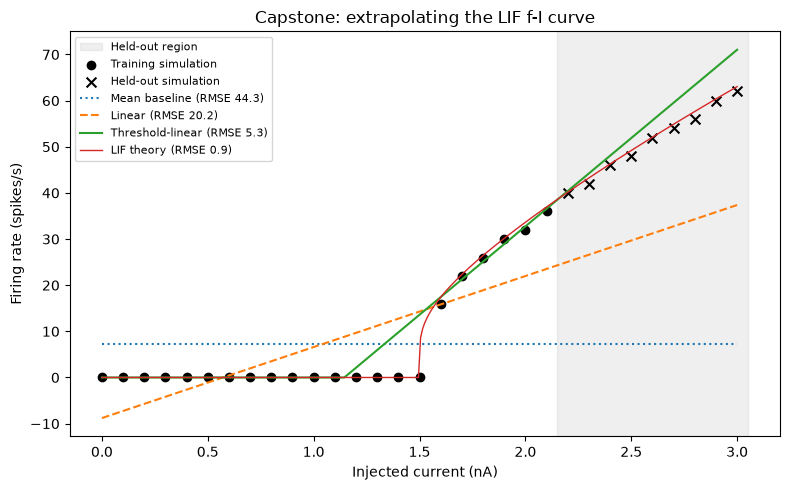

In [2]:
grid = np.linspace(0.0, 3.0, 300)
figure, axis = plt.subplots(figsize=(8, 5))
axis.axvspan(currents[SPLIT] - 0.05, 3.05, color="grey", alpha=0.12, label="Held-out region")
axis.scatter(currents[train], rates[train], color="black", label="Training simulation")
axis.scatter(currents[test], rates[test], color="black", marker="x", s=50, label="Held-out simulation")
axis.plot(grid, np.full(grid.size, rates[train].mean()), ":", label=f"Mean baseline (RMSE {errors['Mean baseline']:.1f})")
axis.plot(grid, linear.predict(grid[:, None]), "--", label=f"Linear (RMSE {errors['Linear (all training points)']:.1f})")
axis.plot(grid, np.maximum(0.0, threshold_linear.predict(grid[:, None])), "-",
          label=f"Threshold-linear (RMSE {errors['Threshold-linear (firing points only)']:.1f})")
axis.plot(grid, lif_firing_rate(grid), "-", linewidth=1, label=f"LIF theory (RMSE {errors['LIF theory (no fitting)']:.1f})")
axis.set(xlabel="Injected current (nA)", ylabel="Firing rate (spikes/s)", title="Capstone: extrapolating the LIF f-I curve")
axis.legend(fontsize=8, loc="upper left")
save_figure(WEEK, figure, "capstone_encoding.png")
save_data(WEEK, "capstone_encoding.npz", current_na=currents, firing_rate_hz=rates, test_indices=test,
          **{name.split(" (")[0].lower().replace(" ", "_").replace("-", "_"): values for name, values in predictions.items()})

## Validación

- Criterio de éxito de la hipótesis.
- La teoría LIF, sin parámetros ajustados, tiene el menor error, y es del orden de la
  resolución de la medida (2 Hz).
- Todos los modelos superan a la línea base.

In [3]:
assert errors["Threshold-linear (firing points only)"] < 0.5 * errors["Linear (all training points)"]
assert min(errors, key=errors.get) == "LIF theory (no fitting)"
assert errors["LIF theory (no fitting)"] < 2.0
assert all(error < errors["Mean baseline"] for name, error in errors.items() if name != "Mean baseline")
for name, error in errors.items():
    print(f"{name}: held-out RMSE {error:.2f} spikes/s")

report = f"""# Capstone report: LIF current-to-rate encoding

## Question
Which simple model best extrapolates the LIF firing rate to currents larger than those used for fitting?

## Methods
- Deterministic LIF model (package defaults), {WINDOW_S * 1000:.0f} ms per current level, rate = count / {WINDOW_S} s.
- Training: {SPLIT} lowest current levels (0-{currents[SPLIT - 1]:.1f} nA). Held out: {currents.size - SPLIT} levels ({currents[SPLIT]:.1f}-3.0 nA).
- Models: mean baseline, linear fit on all training points, threshold-linear fit on firing points only, analytic LIF f-I curve.
- Success criterion (set before analysis): threshold-linear RMSE < 0.5 x linear RMSE.

## Results (held-out RMSE, spikes/s)
""" + "\n".join(f"- {name}: {error:.2f}" for name, error in errors.items()) + """

## Conclusion
The linear model fails because it averages the silent subthreshold region with the firing region.
Fitting only the firing points removes most of that error. The analytic curve, which encodes the
model's mechanism, extrapolates best; its residual error reflects the 2 Hz resolution of a 500 ms count.

## Limitations
Synthetic, deterministic single-neuron data; not experimental evidence. Only one ordered split.

## Reproduction
`python weeks/run_weekly.py 18` (or open weeks/week_18_capstone/week_18_capstone.ipynb). No random seed is needed.
"""
save_text(WEEK, "capstone_report.md", report)

Mean baseline: held-out RMSE 44.34 spikes/s
Linear (all training points): held-out RMSE 20.16 spikes/s
Threshold-linear (firing points only): held-out RMSE 5.34 spikes/s
LIF theory (no fitting): held-out RMSE 0.93 spikes/s
Saved: weeks/week_18_capstone/outputs/capstone_report.md


## Interpretación y límites

- Un modelo con la forma correcta (umbral) importa más que añadir parámetros.
- El umbral-lineal aún sobreestima a corrientes altas porque la curva LIF real es cóncava
  (logarítmica); extrapolar una recta acumula error.
- Los datos son sintéticos y sin ruido: en datos reales, el error de la teoría también incluiría
  variabilidad entre ensayos y error en los parámetros de membrana.

**Entrega final:** este notebook, el informe `capstone_report.md` y la figura cumplen el formato.
Aplica la misma estructura (pregunta, hipótesis previa, modelos, línea base, criterio de éxito,
límites) a tu propia pregunta de la semana 17.